# Práctica de Programación: Clasificación de Textos en Esperanto
**Asignatura:** Minería de Textos (4 INF-A - 2026/2027)

## 1. Introducción y Decisiones de Diseño
Este cuaderno implementa de principio a fin un sistema de Procesamiento de Lenguaje Natural (NLP) y clasificación temática de textos en **Esperanto**, dividido en tres fases:
1. **Fase 1 (Dataset):** Recopilación automática de artículos de Wikipedia en Esperanto mediante su API oficial en tres categorías semánticamente cercanas de **Ciencia**: Física (`fiziko`), Biología (`biologio`) y Química (`kemio`).
2. **Fase 2 (Modelo NLP):** Construcción desde cero de un motor lingüístico basado en reglas gramaticales del Esperanto con interfaz estilo `spaCy` (`EsperantoNLP`, `Doc`, `Token`).
3. **Fase 3 (Clasificación y Web Scraping):** Vectorización TF-IDF sobre los lemas obtenidos, entrenamiento de un clasificador mediante Regresión Logística y evaluación sobre páginas web reales mediante *web scraping*.


In [5]:
import re
import os
import json
import time
import random
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1. Fijar semillas aleatorias para garantizar la reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# 2. Parámetro de ejecución asíncrona:
# True -> Genera el dataset desde el API de Wikipedia y lo guarda en CSV.
# False -> Carga el dataset directamente desde una URL pública de GitHub o fichero local.
GENERAR_DATASET = True
URL_DATASET_REMOTO = "https://raw.githubusercontent.com/tu_usuario/tu_repo/main/dataset_esperanto.csv"
RUTA_CSV = os.path.join(os.path.expanduser("~"), "dataset_esperanto.csv")

# Cabecera User-Agent requerida por Wikipedia para evitar bloqueos HTTP 403
HEADERS = {"User-Agent": "PracticaMineriaTextosCUNEF/1.0 (estudiante@cunef.edu)"}

## 2. Fase 1: Recopilación del Dataset
Se han seleccionado tres categorías del ámbito científico (**física, biología y química**) porque comparten vocabulario académico y estructura enciclopédica, haciendo que la clasificación no sea trivial.

### Tratamiento del ruido por herencia de etiquetas
Al asignar a cada párrafo la categoría general del artículo completo, se introduce **ruido de etiquetado** (por ejemplo, frases cortas de fechas o metadatos como *"Ĝi estis fondita en 1950"*). Para mitigar y medir este ruido:
1. Se limpian etiquetas HTML, referencias entre corchetes (`[1]`), saltos de línea y el carácter delimitador `;`.
2. Se filtran y contabilizan los párrafos demasiado cortos (menos de 60 caracteres o menos de 8 palabras), ya que suelen corresponder a subtítulos, notas o frases genéricas sin carga semántica de la categoría.


In [10]:
WIKI_API_URL = "https://eo.wikipedia.org/w/api.php"

# Categorías en Wikipedia en Esperanto y su etiqueta en el dataset
CATEGORIAS = {
    "Kategorio:Fiziko": "fiziko",
    "Kategorio:Biologio": "biologio",
    "Kategorio:Kemio": "kemio"
}

def obtener_titulos_categoria(categoria_wiki, max_articulos=120):
    """Obtiene títulos de artículos e incluye subcategorías de primer nivel."""
    titulos = []
    subcategorias = [categoria_wiki]
    visitadas = set()

    while subcategorias and len(titulos) < max_articulos:
        cat_actual = subcategorias.pop(0)
        if cat_actual in visitadas:
            continue
        visitadas.add(cat_actual)

        params = {
            "action": "query",
            "list": "categorymembers",
            "cmtitle": cat_actual,
            "cmlimit": 100,
            "format": "json"
        }
        try:
            resp = requests.get(WIKI_API_URL, params=params, headers=HEADERS, timeout=10)
            resp.raise_for_status()
            miembros = resp.json().get("query", {}).get("categorymembers", [])
            for m in miembros:
                if m["ns"] == 0 and m["title"] not in titulos:
                    titulos.append(m["title"])
                elif m["ns"] == 14 and len(subcategorias) < 15:
                    subcategorias.append(m["title"])
        except Exception as e:
            print(f"[Aviso] Error al consultar {cat_actual}: {e}")
            continue

    return titulos[:max_articulos]

def obtener_parrafos_articulo(titulo):
    """Descarga el extracto en texto plano de un artículo y devuelve sus párrafos limpios."""
    params = {
        "action": "query",
        "prop": "extracts",
        "explaintext": True,
        "titles": titulo,
        "format": "json"
    }
    try:
        resp = requests.get(WIKI_API_URL, params=params, headers=HEADERS, timeout=10)
        resp.raise_for_status()
        paginas = resp.json().get("query", {}).get("pages", {})
        for _, info in paginas.items():
            texto = info.get("extract", "")
            return texto.split("\n")
    except Exception as e:
        print(f"[Aviso] Fallo al descargar el artículo '{titulo}': {e}")
    return []

def limpiar_parrafo(p):
    """Limpia HTML, URLs, referencias y elimina el carácter ';' según el contrato de datos."""
    p = re.sub(r"<[^>]+>", " ", p)                  # Eliminar posibles etiquetas HTML
    p = re.sub(r"http\S+|www\.\S+", " ", p)         # Eliminar enlaces web
    p = re.sub(r"\[\d+\]", " ", p)                  # Eliminar referencias tipo [1]
    p = re.sub(r"^=+.*?=+$", " ", p)                # Eliminar cabeceras de sección (== Historia ==)
    p = p.replace(";", ",")                         # Prohibido incluir ';' en el texto
    p = re.sub(r"\s+", " ", p).strip()              # Normalizar espacios
    return p

def construir_dataset(objetivo_por_clase=350):
    filas = []
    ruido_descartado = 0
    total_brutos = 0

    for cat_wiki, etiqueta in CATEGORIAS.items():
        print(f"Descargando artículos para la clase '{etiqueta}'...")
        titulos = obtener_titulos_categoria(cat_wiki, max_articulos=150)
        contador_clase = 0

        for titulo in titulos:
            if contador_clase >= objetivo_por_clase:
                break
            parrafos = obtener_parrafos_articulo(titulo)
            for p in parrafos:
                total_brutos += 1
                p_limpio = limpiar_parrafo(p)
                # Medición y filtrado de ruido: descartar párrafos cortos o genéricos
                if len(p_limpio) < 60 or len(p_limpio.split()) < 8:
                    ruido_descartado += 1
                    continue
                filas.append({"text": p_limpio, "class": etiqueta})
                contador_clase += 1

        print(f" -> Clase '{etiqueta}': {contador_clase} párrafos válidos recopilados.")

    porcentaje_ruido = (ruido_descartado / max(1, total_brutos)) * 100
    print(f"\n[Análisis de Ruido] Párrafos brutos: {total_brutos} | Descartados por ruido/longitud: {ruido_descartado} ({porcentaje_ruido:.1f}%)")

    df = pd.DataFrame(filas).drop_duplicates(subset=["text"])
    df.to_csv(RUTA_CSV, sep=";", index=False, encoding="utf-8")
    return df

# Ejecución controlada por parámetro
if GENERAR_DATASET:
    df_dataset = construir_dataset(objetivo_por_clase=350)
else:
    try:
        df_dataset = pd.read_csv(URL_DATASET_REMOTO, sep=";", encoding="utf-8")
    except Exception:
        df_dataset = pd.read_csv(RUTA_CSV, sep=";", encoding="utf-8")

print("\nDistribución final del dataset:")
print(df_dataset["class"].value_counts())
df_dataset.head()


Descargando artículos para la clase 'fiziko'...
 -> Clase 'fiziko': 382 párrafos válidos recopilados.
Descargando artículos para la clase 'biologio'...
 -> Clase 'biologio': 357 párrafos válidos recopilados.
Descargando artículos para la clase 'kemio'...
 -> Clase 'kemio': 357 párrafos válidos recopilados.

[Análisis de Ruido] Párrafos brutos: 7199 | Descartados por ruido/longitud: 6103 (84.8%)

Distribución final del dataset:
class
fiziko      380
biologio    357
kemio       341
Name: count, dtype: int64


,text,class
0,"Fiziko estas la naturscienco, kiu priskribas l...",fiziko
1,Fizikistoj ellaboras teoriojn pri la konsistaĵ...,fiziko
2,Malkovroj en la kampo de fiziko trovas ofte ap...,fiziko
3,"La fizikistoj observas, mezuras kaj modeligas ...",fiziko
4,"La teorioj, bone fonditaj aŭ ne, enhavas leĝoj...",fiziko


## 3. Fase 2: Modelo de NLP en Esperanto basado en Reglas
Aprovechando que el Esperanto tiene una gramática 100% regular y sin excepciones, implementamos desde cero las clases `Token`, `Doc` y `EsperantoNLP` siguiendo la interfaz de `spaCy`:
- **Sustantivos (`NOUN`):** Terminan en `-o` (plural `-oj`, acusativo `-on`, plural acusativo `-ojn`). Su lema se obtiene restituyendo la terminación `-o`.
- **Adjetivos (`ADJ`):** Terminan en `-a` (`-aj`, `-an`, `-ajn`). Su lema restituye la terminación `-a`.
- **Adverbios derivados (`ADV`):** Terminan en `-e` (`-en`). Su lema restituye la terminación `-e`.
- **Verbos (`VERB`):** Terminan en `-i` (infinitivo), `-as` (presente), `-is` (pasado), `-os` (futuro), `-us` (condicional) o `-u` (imperativo). Su lema normaliza la raíz a la forma infinitiva en `-i`.


In [7]:
def cargar_stopwords_esperanto():
    """Carga las stop-words desde el repositorio guía del profesor con fallback local."""
    url_vortoj = "https://raw.githubusercontent.com/jparisu/nlp-esperantilo/main/resources/esperanto/vortoj.json"
    stopwords_base = {
        "la", "kaj", "de", "en", "al", "mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni",
        "si", "kun", "por", "per", "pri", "pro", "sur", "sub", "inter", "antaŭ", "post",
        "ĉirkaŭ", "ĝis", "el", "ekster", "krom", "sen", "tra", "trans", "ne", "jes",
        "ke", "ĉar", "se", "sed", "aŭ", "ankaŭ", "ankoraŭ", "jam", "nun", "tuj", "tre",
        "tro", "pli", "plej", "kiel", "tiel", "kiu", "tiu", "kio", "tio", "kia", "tia",
        "kie", "tie", "kiam", "tiam", "kiom", "tiom", "ĉiu", "ĉio", "neniu", "nenio",
        "unu", "du", "tri", "estis", "estas", "estos", "esti", "havis", "havas"
    }
    try:
        resp = requests.get(url_vortoj, timeout=8)
        resp.raise_for_status()
        datos = resp.json()
        # Extraer palabras funcionales del JSON si existen listas o diccionarios
        if isinstance(datos, dict):
            for clave, valor in datos.items():
                if isinstance(valor, list):
                    stopwords_base.update([str(w).lower() for w in valor])
                elif isinstance(valor, dict):
                    stopwords_base.update([str(k).lower() for k in valor.keys()])
        elif isinstance(datos, list):
            stopwords_base.update([str(w).lower() for w in datos])
    except Exception as e:
        print(f"[Aviso] Usando lista interna de stop-words (no se pudo descargar vortoj.json: {e})")
    return stopwords_base


class Token:
    """Representa un token individual con atributos inspirados en spaCy."""
    def __init__(self, text, lemma, pos, is_stop, is_punct, is_alpha):
        self.text = text
        self.lemma_ = lemma
        self.pos_ = pos
        self.is_stop = is_stop
        self.is_punct = is_punct
        self.is_alpha = is_alpha

    def __repr__(self):
        return f"Token(text='{self.text}', lemma_='{self.lemma_}', pos_='{self.pos_}', is_stop={self.is_stop})"


class Doc:
    """Contenedor iterable de objetos Token similar al objeto Doc de spaCy."""
    def __init__(self, text, tokens):
        self.text = text
        self._tokens = tokens

    def __iter__(self):
        return iter(self._tokens)

    def __getitem__(self, idx):
        return self._tokens[idx]

    def __len__(self):
        return len(self._tokens)

    def __repr__(self):
        return f"Doc({len(self._tokens)} tokens: '{self.text[:50]}...')"


class EsperantoNLP:
    """Motor de NLP basado en reglas morfológicas del Esperanto."""
    def __init__(self):
        self.stopwords = cargar_stopwords_esperanto()
        # Expresión regular que separa palabras (incluyendo caracteres del Esperanto: ĉ, ĝ, ĥ, ĵ, ŝ, ŭ) y signos de puntuación
        self.patron_token = re.compile(r"[a-zA-ZĉĝĥĵŝŭĈĜĤĴŜŬ]+|\d+|[^\w\s]", re.UNICODE)

    def _analizar_morfologia(self, palabra_Original):
        w = palabra_Original.lower()

        # 1. Signos de puntuación
        if not w.isalpha():
            if w.isdigit():
                return w, "NUM", False, False, False
            return w, "PUNCT", False, True, False

        es_stop = w in self.stopwords

        # 2. Stop-words o palabras muy cortas (preposiciones, conjunciones, pronombres)
        if es_stop or len(w) <= 2:
            return w, "PRON/PART" if es_stop else "X", es_stop, False, True

        # 3. Reglas de Sustantivos (terminaciones -ojn, -on, -oj, -o)
        for suf in ("ojn", "on", "oj", "o"):
            if w.endswith(suf) and len(w) > len(suf) + 1:
                lema = w[:-len(suf)] + "o"
                return lema, "NOUN", (lema in self.stopwords or es_stop), False, True

        # 4. Reglas de Adjetivos (terminaciones -ajn, -an, -aj, -a)
        for suf in ("ajn", "an", "aj", "a"):
            if w.endswith(suf) and len(w) > len(suf) + 1:
                lema = w[:-len(suf)] + "a"
                return lema, "ADJ", (lema in self.stopwords or es_stop), False, True

        # 5. Reglas de Verbos (terminaciones -as, -is, -os, -us, -u, -i)
        for suf in ("as", "is", "os", "us", "u", "i"):
            if w.endswith(suf) and len(w) > len(suf) + 1:
                lema = w[:-len(suf)] + "i"
                return lema, "VERB", (lema in self.stopwords or es_stop), False, True

        # 6. Reglas de Adverbios derivados (terminaciones -en, -e)
        for suf in ("en", "e"):
            if w.endswith(suf) and len(w) > len(suf) + 1:
                lema = w[:-len(suf)] + "e"
                return lema, "ADV", (lema in self.stopwords or es_stop), False, True

        # 7. Resto de palabras
        return w, "X", es_stop, False, True

    def __call__(self, texto):
        matches = self.patron_token.findall(texto)
        tokens = []
        for m in matches:
            lema, pos, is_stop, is_punct, is_alpha = self._analizar_morfologia(m)
            tokens.append(Token(m, lema, pos, is_stop, is_punct, is_alpha))
        return Doc(texto, tokens)


# Instanciar y probar el modelo NLP
nlp = EsperantoNLP()
doc_prueba = nlp("La fizikistoj studis la grandajn atomojn kaj kemiajn reakciojn rapide.")

print("Demostración del API estilo spaCy:")
for token in doc_prueba:
    print(f"{token.text:<12} | Lema: {token.lemma_:<12} | POS: {token.pos_:<9} | Stop: {token.is_stop}")


Demostración del API estilo spaCy:
La           | Lema: la           | POS: PRON/PART | Stop: True
fizikistoj   | Lema: fizikisto    | POS: NOUN      | Stop: False
studis       | Lema: studi        | POS: VERB      | Stop: False
la           | Lema: la           | POS: PRON/PART | Stop: True
grandajn     | Lema: granda       | POS: ADJ       | Stop: False
atomojn      | Lema: atomo        | POS: NOUN      | Stop: False
kaj          | Lema: kaj          | POS: PRON/PART | Stop: True
kemiajn      | Lema: kemia        | POS: ADJ       | Stop: False
reakciojn    | Lema: reakcio      | POS: NOUN      | Stop: False
rapide       | Lema: rapide       | POS: ADV       | Stop: False
.            | Lema: .            | POS: PUNCT     | Stop: False


## 4. Fase 3: Clasificación de Textos y Evaluación
Para construir la representación tabular del corpus:
1. Procesamos cada párrafo con nuestro modelo `EsperantoNLP`, conservando únicamente los lemas alfabéticos (`token.is_alpha`) que no sean *stop-words* (`not token.is_stop`).
2. Transformamos los textos lematizados mediante **TF-IDF** (`TfidfVectorizer`).
3. Dividimos el dataset en entrenamiento (80%) y test (20%) de forma estratificada y entrenamos un modelo de **Regresión Logística**, evaluando con **Accuracy**, **F1 Macro** y **Matriz de Confusión**.


Preprocesando y lematizando el dataset con EsperantoNLP...
=== Resultados de Evaluación en Test ===
Accuracy : 0.8843
F1 Macro : 0.8860

Informe detallado por clase:
              precision    recall  f1-score   support

    biologio       0.90      0.88      0.89        72
      fiziko       0.83      0.88      0.85        76
       kemio       0.94      0.90      0.92        68

    accuracy                           0.88       216
   macro avg       0.89      0.88      0.89       216
weighted avg       0.89      0.88      0.88       216



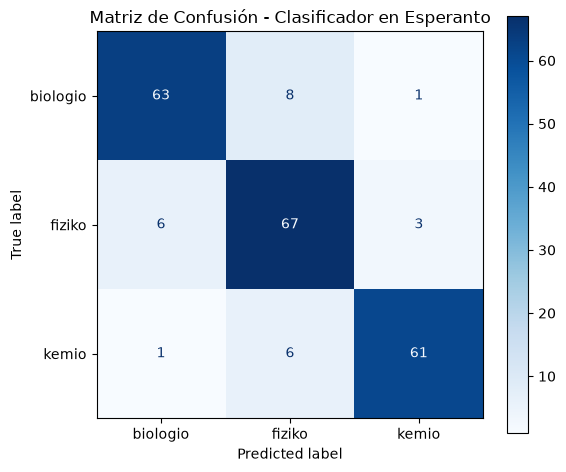

In [11]:
def preprocesar_con_nlp(texto):
    """Devuelve los lemas limpios separados por espacios usando nuestro modelo EsperantoNLP."""
    doc = nlp(str(texto))
    lemas = [t.lemma_ for t in doc if t.is_alpha and not t.is_stop and len(t.lemma_) > 2]
    return " ".join(lemas)

print("Preprocesando y lematizando el dataset con EsperantoNLP...")
df_dataset["text_lemmas"] = df_dataset["text"].apply(preprocesar_con_nlp)

# Partición Train / Test estratificada
X_train, X_test, y_train, y_test = train_test_split(
    df_dataset["text_lemmas"],
    df_dataset["class"],
    test_size=0.20,
    random_state=SEED,
    stratify=df_dataset["class"]
)

# Vectorización TF-IDF
vectorizador = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizador.fit_transform(X_train)
X_test_tfidf = vectorizador.transform(X_test)

# Entrenamiento del clasificador
modelo_clf = LogisticRegression(random_state=SEED, max_iter=1000)
modelo_clf.fit(X_train_tfidf, y_train)

# Predicción y evaluación
y_pred = modelo_clf.predict(X_test_tfidf)
acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"=== Resultados de Evaluación en Test ===")
print(f"Accuracy : {acc:.4f}")
print(f"F1 Macro : {f1_macro:.4f}\n")
print("Informe detallado por clase:")
print(classification_report(y_test, y_pred))

# Visualización de la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax)
plt.title("Matriz de Confusión - Clasificador en Esperanto")
plt.tight_layout()
plt.show()


## 5. Clasificación de Páginas Web Reales (Web Scraping)
Para comprobar el funcionamiento del modelo en un entorno real, extraemos mediante `requests` y `BeautifulSoup` el contenido HTML de páginas web en Esperanto correspondientes a las tres temáticas elegidas, filtramos sus párrafos y calculamos la probabilidad predicha para cada categoría.


In [12]:
URLS_PRUEBA = [
    ("https://eo.wikipedia.org/wiki/Kvantuma_mekaniko", "fiziko"),
    ("https://eo.wikipedia.org/wiki/Fotosintezo", "biologio"),
    ("https://eo.wikipedia.org/wiki/Perioda_tabelo", "kemio")
]

def clasificar_pagina_web(url):
    """Extrae el texto de una página web mediante BeautifulSoup y predice la probabilidad de cada clase."""
    try:
        resp = requests.get(url, headers=HEADERS, timeout=10)
        resp.raise_for_status()
        soup = BeautifulSoup(resp.text, "html.parser")

        # Extraer texto de los párrafos HTML <p>
        parrafos_html = [limpiar_parrafo(p.get_text()) for p in soup.find_all("p")]
        parrafos_validos = [p for p in parrafos_html if len(p) >= 60]

        if not parrafos_validos:
            print(f"[Aviso] No se encontró texto suficiente en {url}")
            return None

        texto_completo = " ".join(parrafos_validos)
        texto_lematizado = preprocesar_con_nlp(texto_completo)
        vector_web = vectorizador.transform([texto_lematizado])

        probabilidades = modelo_clf.predict_proba(vector_web)[0]
        clase_predicha = modelo_clf.classes_[np.argmax(probabilidades)]

        return {
            "url": url,
            "prediccion": clase_predicha,
            "probabilidades": dict(zip(modelo_clf.classes_, np.round(probabilidades, 4)))
        }
    except Exception as e:
        print(f"[Error controlado] No se pudo procesar la web {url}: {e}")
        return None

print("=== Clasificación de Páginas Web en Entorno Real ===\n")
for url, categoria_esperada in URLS_PRUEBA:
    resultado = clasificar_pagina_web(url)
    if resultado:
        print(f"URL: {resultado['url']}")
        print(f" -> Categoría esperada : {categoria_esperada}")
        print(f" -> Categoría predicha : {resultado['prediccion']}")
        print(f" -> Probabilidades     : {resultado['probabilidades']}\n")


=== Clasificación de Páginas Web en Entorno Real ===

URL: https://eo.wikipedia.org/wiki/Kvantuma_mekaniko
 -> Categoría esperada : fiziko
 -> Categoría predicha : fiziko
 -> Probabilidades     : {'biologio': np.float64(0.1275), 'fiziko': np.float64(0.7066), 'kemio': np.float64(0.1658)}

URL: https://eo.wikipedia.org/wiki/Fotosintezo
 -> Categoría esperada : biologio
 -> Categoría predicha : kemio
 -> Probabilidades     : {'biologio': np.float64(0.143), 'fiziko': np.float64(0.0765), 'kemio': np.float64(0.7805)}

URL: https://eo.wikipedia.org/wiki/Perioda_tabelo
 -> Categoría esperada : kemio
 -> Categoría predicha : kemio
 -> Probabilidades     : {'biologio': np.float64(0.0814), 'fiziko': np.float64(0.1244), 'kemio': np.float64(0.7943)}

